# Starbucks Customer Segmentation — Simple College Version

### Project Goal
This notebook uses the Starbucks customer dataset to:
- load the customer and transaction data,
- do a small amount of data cleaning,
- understand basic customer behavior,
- group customers into **5 simple customer segments using K-Means**,
- visualize and understand the groups.

> **Note:** This simplified version intentionally does **not** use Feature Engineering, StandardScaler, or Silhouette Score. The focus is on keeping the project easy to understand and explain in a college viva.

## Cell 1 — Import Libraries

We import only the libraries needed for this simple project.

- **Pandas** → work with tables/data.
- **NumPy** → basic numerical operations.
- **Matplotlib** → create graphs.
- **Seaborn** → make graphs easier to create.
- **KMeans** → group similar customers into clusters.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans

## Cell 2 — Load the Datasets

The project uses three Starbucks files:

- `portfolio.csv` → information about offers.
- `profile.csv` → customer information.
- `transcript.csv` → customer activities such as receiving/viewing/completing offers and making transactions.

The files should be in the **same folder as this notebook**.

In [ ]:
df_offer = pd.read_csv('portfolio.csv')
df_customer = pd.read_csv('profile.csv')
df_transcript = pd.read_csv('transcript.csv')

print("Offer data:", df_offer.shape)
print("Customer data:", df_customer.shape)
print("Transcript data:", df_transcript.shape)

## Cell 3 — Look at the Data

`head()` shows the first few rows. This helps us understand what columns are present before cleaning the data.

In [ ]:
print("Offer Data")
display(df_offer.head())

print("Customer Data")
display(df_customer.head())

print("Transcript Data")
display(df_transcript.head())

## Cell 4 — Remove the Unnecessary Index Column

When CSV files are saved from another notebook, a column called `Unnamed: 0` can sometimes appear.

It is only an old row index, so we remove it if it exists.

`errors='ignore'` prevents an error if the column has already been removed.

In [ ]:
for df in [df_offer, df_customer, df_transcript]:
    df.drop(columns=['Unnamed: 0'], errors='ignore', inplace=True)

print("Unnecessary index columns removed.")

## Cell 5 — Check Missing Customer Information

Some customers have missing `gender` or `income`.

For this simple project, we remove customers where these two important fields are missing.

This keeps the customer data easy to work with.

In [ ]:
print("Missing values before cleaning:")
print(df_customer[['gender', 'income']].isnull().sum())

df_customer = df_customer.dropna(
    subset=['gender', 'income']
).reset_index(drop=True)

print("\nMissing values after cleaning:")
print(df_customer[['gender', 'income']].isnull().sum())

## Cell 6 — Basic Customer Information

Here we calculate two simple values:

- average customer age,
- average customer income.

This gives us a quick idea about the customers in the dataset.

In [ ]:
print("Average Age:", round(df_customer['age'].mean(), 1))
print("Average Income:", round(df_customer['income'].mean(), 1))

## Cell 7 — Customer Age Distribution

This graph shows how customers are distributed by age.

The X-axis represents age and the Y-axis represents the number of customers.

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df_customer['age'], bins=20)

plt.title('Customer Age Distribution')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

## Cell 8 — Understand Transcript Values

The `value` column contains information stored as text that looks like a Python dictionary.

For example, a transaction can contain an `amount`, while an offer event can contain an `offer id`.

We convert this text into actual Python dictionaries so we can easily read the information.

In [ ]:
import ast

df_transcript['value'] = df_transcript['value'].apply(
    ast.literal_eval
)

df_transcript.head()

## Cell 9 — Extract Transaction Amount

For transaction rows, the dictionary contains an `amount`.

We create an `amount` column:
- transaction → actual amount,
- other events → 0.

This allows us to calculate total money spent by each customer.

In [ ]:
df_transcript['amount'] = df_transcript['value'].apply(
    lambda x: x.get('amount', 0)
)

df_transcript[['person', 'event', 'amount']].head()

## Cell 10 — Count Customer Activities

We count four simple types of customer activity for every customer:

- `num_received` → offers received.
- `num_viewed` → offers viewed.
- `num_completed` → offers completed.
- `num_transactions` → transactions made.

This is the main customer behavior information used for clustering.

In [ ]:
received = (
    df_transcript[df_transcript['event'] == 'offer received']
    .groupby('person')
    .size()
    .rename('num_received')
)

viewed = (
    df_transcript[df_transcript['event'] == 'offer viewed']
    .groupby('person')
    .size()
    .rename('num_viewed')
)

completed = (
    df_transcript[df_transcript['event'] == 'offer completed']
    .groupby('person')
    .size()
    .rename('num_completed')
)

transactions = (
    df_transcript[df_transcript['event'] == 'transaction']
    .groupby('person')
    .size()
    .rename('num_transactions')
)

print("Activity counts created.")

## Cell 11 — Calculate Total Money Spent

Here we add the transaction amounts for every customer.

For example, if a customer spent $10, $15 and $20, their total `money_spent` is $45.

In [ ]:
money_spent = (
    df_transcript[df_transcript['event'] == 'transaction']
    .groupby('person')['amount']
    .sum()
    .rename('money_spent')
)

money_spent.head()

## Cell 12 — Create the Customer Behavior Table

We combine all the activity counts and total spending into one table.

`fillna(0)` means that if a customer has no activity of a particular type, we use 0 instead of leaving it blank.

In [ ]:
customer_behavior = pd.concat(
    [
        received,
        viewed,
        completed,
        transactions,
        money_spent
    ],
    axis=1
).fillna(0)

customer_behavior.head()

## Cell 13 — Choose Simple Clustering Data

We use five easy-to-understand customer behavior columns:

1. offers received,
2. offers viewed,
3. offers completed,
4. number of transactions,
5. money spent.

These values are given directly to K-Means in this simplified college version.

In [ ]:
features = [
    'num_received',
    'num_viewed',
    'num_completed',
    'num_transactions',
    'money_spent'
]

X = customer_behavior[features]

print("Features used for clustering:")
print(features)

## Cell 14 — Create K-Means Model

We choose **5 clusters**.

K-Means will try to divide customers into five groups based on their behavior.

The cluster numbers are simply labels: Cluster 0, Cluster 1, etc. A higher cluster number does **not** automatically mean a better customer.

In [ ]:
k = 5

kmeans = KMeans(
    n_clusters=k,
    random_state=10,
    n_init=10
)

customer_behavior['cluster'] = kmeans.fit_predict(X)

print("K-Means clustering completed.")

## Cell 15 — Number of Customers in Each Cluster

This tells us how many customers were placed into each of the five groups.

In [ ]:
cluster_counts = (
    customer_behavior['cluster']
    .value_counts()
    .sort_index()
)

print("Customers in each cluster:")
print(cluster_counts)

## Cell 16 — Understand Each Cluster

We calculate the average behavior of customers in each cluster.

This helps us describe the groups in simple terms, such as:
- customers with lower spending,
- customers who view many offers,
- customers with many transactions,
- customers with higher spending.

In [ ]:
cluster_summary = (
    customer_behavior
    .groupby('cluster')[features]
    .mean()
    .round(2)
)

cluster_summary

## Cell 17 — Customer Segmentation Graph

This scatter plot shows the relationship between:

- **X-axis:** Money Spent
- **Y-axis:** Offers Viewed
- **Color:** Customer Cluster

Customers with similar behavior should appear closer together.

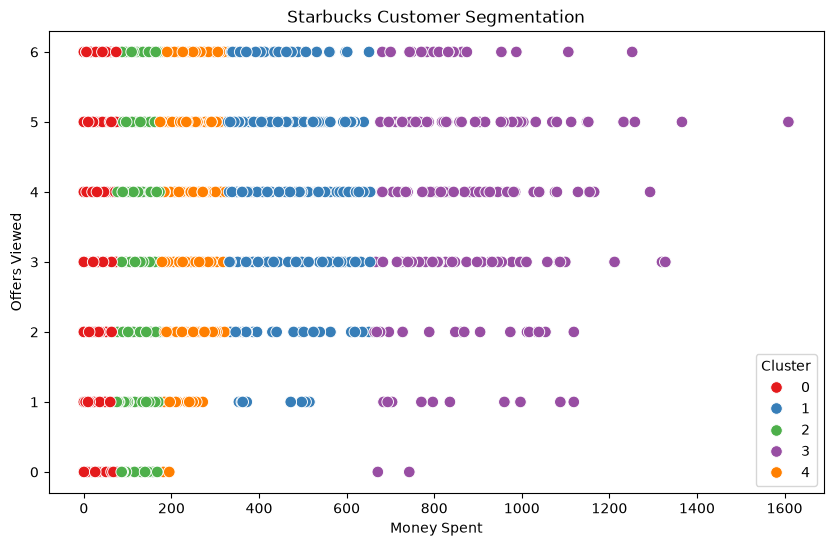

In [25]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_behavior,
    x='money_spent',
    y='num_viewed',
    hue='cluster',
    palette='Set1',
    s=70
)

plt.title('Starbucks Customer Segmentation')
plt.xlabel('Money Spent')
plt.ylabel('Offers Viewed')
plt.legend(title='Cluster')
plt.show()

## Cell 18 — Cluster Size Graph

This bar chart shows how many customers are present in each cluster.

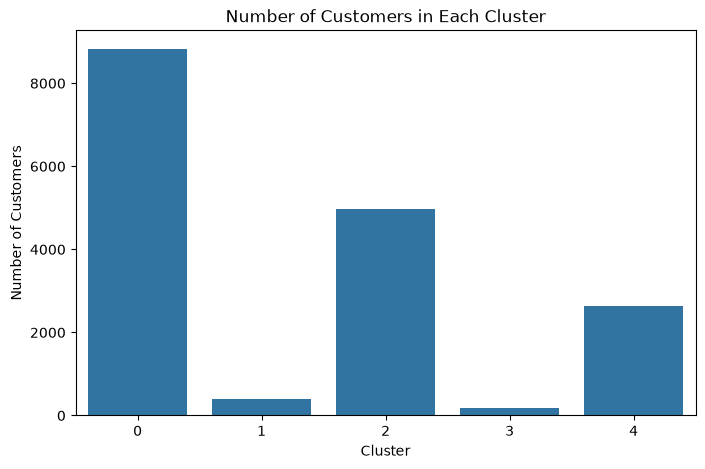

In [24]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_behavior,
    x='cluster'
)

plt.title('Number of Customers in Each Cluster')
plt.xlabel('Cluster')
plt.ylabel('Number of Customers')
plt.show()

## Cell 19 — Simple Cluster Interpretation

The exact meaning of each cluster should be decided by looking at the averages in the previous table.

For example, a cluster with high `money_spent` and high `num_transactions` can be described as a **high-value / frequent customer group**.

Do not assume Cluster 0 is always the lowest-value group; K-Means assigns cluster numbers automatically.

In [26]:
print("Cluster Summary")
display(cluster_summary)

print("Customer Segment Interpretation")
print("- Cluster 0 → Low-Value Customers")
print("- Cluster 1 → Highly Active Customers")
print("- Cluster 2 → Regular Customers")
print("- Cluster 3 → High-Value Customers")
print("- Cluster 4 → Frequent Customers")

Cluster Summary


,num_received,num_viewed,num_completed,num_transactions,money_spent
cluster,,,,,
0,4.43,3.20,0.90,6.69,27.95
1,4.88,4.07,3.83,14.07,426.95
2,4.43,3.46,2.81,8.36,120.88
3,4.65,3.76,3.50,10.60,899.50
4,4.69,3.83,3.63,11.77,226.94


Customer Segment Interpretation
- Cluster 0 → Low-Value Customers
- Cluster 1 → Highly Active Customers
- Cluster 2 → Regular Customers
- Cluster 3 → High-Value Customers
- Cluster 4 → Frequent Customers


## Cell 20 — Final Conclusion

The project uses customer activity and spending information to divide Starbucks customers into five groups using K-Means.

### What we learned
- Customer data contains demographic and activity information.
- Customer behavior can be summarized using offer and transaction counts.
- K-Means can group customers with similar behavior.
- The cluster summary helps us understand the characteristics of each group.

### Project benefit
Starbucks can use these customer groups to understand customer behavior and design more suitable marketing offers.

In [22]:
print("Starbucks Customer Segmentation Project Completed!")
print("Customers analyzed:", len(customer_behavior))
print("Number of clusters:", k)

Starbucks Customer Segmentation Project Completed!
Customers analyzed: 17000
Number of clusters: 5
